# Detección de defectos en infraestructuras (`Corrosion-bi3q3`) con Faster R-CNN v2

**Asignatura:** Visión por Computador — USC (2026/2027)  
**Dataset asignado:** `Francesco/corrosion-bi3q3` (Roboflow-100, partición corregida `slippage_validation_split`)  
**Detector analizado:** Faster R-CNN v2 (`fasterrcnn_resnet50_fpn_v2`, pesos `COCO_V1` de `torchvision`)

Este cuaderno reúne los resultados, gráficas y análisis necesarios para la **exposición oral**, con una comparación a **12 épocas** y una ampliación posterior a **20 épocas** para la variante de resolución:
1. Descripción del dataset y del detector Faster R-CNN v2.
2. Metodología y resultados del **baseline** (curvas de entrenamiento, mAP, curvas PR y tiempos de inferencia).
3. **Estrategias de mejora propuestas** (hipótesis técnicas y modificaciones).
4. **Evolución y comparativa cuantitativa en validación** (resultados de referencia, nuevas variantes cruzadas e inferencia) y **análisis por técnica**.
5. **Análisis cualitativo** (aciertos, fallos frecuentes y comparativa visual *Baseline vs E6*).
6. Preparación del **Ensemble WBF** con RetinaNet v2.
7. **Evaluación final en `test`** (configuraciones seleccionadas en validación) y conclusiones.

In [1]:
import json
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from matplotlib.patches import Rectangle

# Localizar la raíz del proyecto tanto desde la raíz como desde notebooks/
RAIZ = Path.cwd()
if not (RAIZ / "src").exists():
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src.dataset import CorrosionDataset, NOMBRES_CLASES, PARTICIONES
from src.evaluar import cargar_predicciones, _iou_entre_cajas

DIR_RESULTADOS = RAIZ / "results" / "slippage_validation_split"
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 200,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
})

COLORES_CLASE = {
    1: "#2563EB",  # Slippage (azul)
    2: "#DC2626",  # corrosion (rojo)
    3: "#EA580C",  # crack (naranja)
}

# Paleta unificada para todas las gráficas y la presentación PowerPoint
COLORES_EXP = {
    "Baseline (Faster R-CNN v2)": "#2563EB",
    "E1: Data Augmentation": "#0891B2",
    "E2: Transfer Learning": "#64748B",
    "E3a: SGD + MultiStepLR": "#92400E",
    "E3b: Anchors pequeños + 960 px": "#EA580C",
    "E4: Pérdida CIoU + CE ponderada": "#059669",
    "E5a: Ajuste NMS + Confianza": "#9333EA",
    "E5b: TTA WBF (orig + hflip + vflip)": "#7C3AED",
    "E6: Ensemble WBF (E1 + E3b + E4)": "#DC2626",
}

NOMBRE_BASELINE = "Baseline (Faster R-CNN v2)"
EXPERIMENTOS = {
    NOMBRE_BASELINE: {
        "dir": DIR_RESULTADOS / "faster_rcnn",
        "categoria": "Baseline",
    },
    "E1: Data Augmentation": {
        "dir": DIR_RESULTADOS / "exp01_data_augmentation",
        "categoria": "Aumento de datos",
    },
    "E2: Transfer Learning": {
        "dir": DIR_RESULTADOS / "exp02_transfer_learning",
        "categoria": "Transfer learning",
    },
    "E3a: SGD + MultiStepLR": {
        "dir": DIR_RESULTADOS / "exp03_sgd_multistep",
        "categoria": "Optimizador",
    },
    "E3b: Anchors pequeños + 960 px": {
        "dir": DIR_RESULTADOS / "exp04_anchors_resolucion",
        "categoria": "Anchors / Resolución",
    },
    "E4: Pérdida CIoU + CE ponderada": {
        "dir": DIR_RESULTADOS / "exp05_perdidas_ciou_ponderada",
        "categoria": "Funciones de pérdida",
    },
    "E5a: Ajuste NMS + Confianza": {
        "dir": DIR_RESULTADOS / "exp06_postprocesado_nms",
        "categoria": "Post-procesado",
    },
    "E5b: TTA WBF (orig + hflip + vflip)": {
        "dir": DIR_RESULTADOS / "exp07_tta_wbf",
        "categoria": "Inferencia (TTA)",
    },
    "E6: Ensemble WBF (E1 + E3b + E4)": {
        "dir": DIR_RESULTADOS / "exp08_ensemble_wbf",
        "categoria": "Ensemble WBF",
    },
}


def leer_json(ruta: Path):
    if not ruta.exists():
        return None
    with ruta.open(encoding="utf-8") as f:
        return json.load(f)


def cargar_metricas(dir_exp: Path, particion: str = "validation") -> dict | None:
    rutas = [dir_exp / f"metricas_{particion}.json"]
    if particion == "test":
        rutas.insert(0, dir_exp / "metricas_test_final.json")
    for ruta in rutas:
        datos = leer_json(ruta)
        if isinstance(datos, dict):
            m = datos.get(particion, datos)
            if isinstance(m, dict) and "map" in m:
                return m
    return None


print(f"Resultados: {DIR_RESULTADOS}")
print(f"Figuras:    {DIR_FIGURAS}")

C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Resultados: C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\results\slippage_validation_split
Figuras:    C:\Users\jparp\Mi unidad\USC\Visión por Computador\Práctica 6\deteccion-corrosion\results\slippage_validation_split\figuras


---
## 1. Descripción del dataset (`Corrosion-bi3q3`) y del modelo Faster R-CNN v2

### Particularidades clave del dataset
- **Partición corregida (`slippage_validation_split`):** por indicación del profesor se trasladaron 20 imágenes completas con `Slippage` desde `train` a `validation` (originalmente `validation` tenía 0 instancias de `Slippage`). Todas las pruebas se ejecutan con esta división (`train=820`, `validation=125`, `test=304`, ver [manifiesto](../configs/particiones/slippage_validation_split.json)).
- **Resolución uniforme e imágenes negativas:** todas las imágenes son de `640 × 640` píxeles y existen imágenes sin defectos en las tres particiones (`37 / 5 / 13`).
- **Desequilibrio entre clases:** la clase `0` (`corrosion-0`) carece de anotaciones y se reserva para el fondo. En `train`, `Slippage` (`499`) tiene menos de la mitad de instancias que `corrosion` (`1.175`) y `crack` (`1.388`).
- **Objetos muy pequeños y alargados:** el **85,2 %** de las cajas tienen área inferior a `32² = 1.024 px²` (mediana `231 px²`), y las grietas (`crack`) muestran relaciones de aspecto muy extremas (`97,6 %` en el rango `small`), lo que supone el principal reto visual.

### Arquitectura: Faster R-CNN v2 (`ResNet-50 + FPN v2`)
- Detector **two-stage** preentrenado en MS COCO (`FasterRCNN_ResNet50_FPN_V2_Weights.COCO_V1`, **46,7 AP en COCO**).
- **Etapa 1 (RPN):** genera propuestas de regiones candidatas sobre los 5 niveles de la pirámide FPN (`P2–P6`).
- **Etapa 2 (RoI Heads):** extrae características mediante `MultiScaleRoIAlign` y clasifica + refina cajas con `FastRCNNPredictor` adaptado a **4 clases** (`fondo`, `Slippage`, `corrosion`, `crack`).

,Partición,Imágenes,Sin objetos,Slippage,corrosion,crack,Total objetos
0,train,820,37,499,1175,1388,3062
1,validation,125,5,49,165,258,472
2,test,304,13,98,317,867,1282


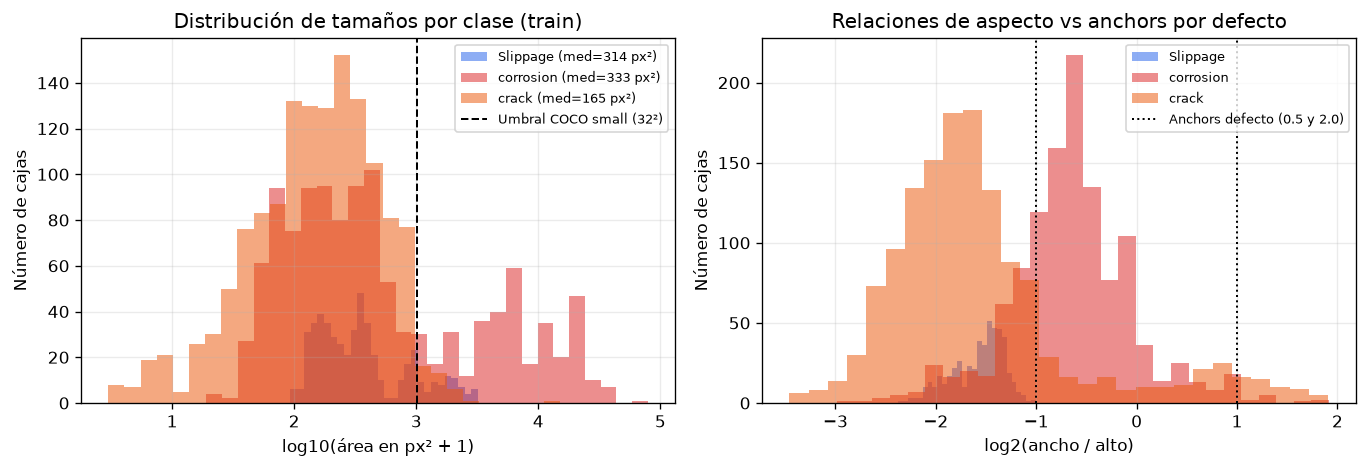

In [2]:
# Resumen de particiones y distribución de tamaños / relaciones de aspecto (train)
filas_resumen = []
areas_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}
ratios_por_clase = {nombre: [] for nombre in NOMBRES_CLASES.values()}

for particion in PARTICIONES:
    datos = CorrosionDataset(particion).datos
    cont = Counter()
    vacias = 0
    for objetos in datos["objects"]:
        cajas, cats = objetos["bbox"], objetos["category"]
        if len(cajas) == 0:
            vacias += 1
        cont.update(cats)
        if particion == "train":
            for (x, y, w, h), cat in zip(cajas, cats):
                nombre = NOMBRES_CLASES[cat]
                areas_por_clase[nombre].append(w * h)
                ratios_por_clase[nombre].append(w / max(h, 1e-6))

    filas_resumen.append({
        "Partición": particion,
        "Imágenes": len(datos),
        "Sin objetos": vacias,
        "Slippage": cont.get(1, 0),
        "corrosion": cont.get(2, 0),
        "crack": cont.get(3, 0),
        "Total objetos": sum(cont.values()),
    })

display(pd.DataFrame(filas_resumen))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.0))
colores_nombre = {NOMBRES_CLASES[k]: v for k, v in COLORES_CLASE.items()}
for nombre, areas in areas_por_clase.items():
    axes[0].hist(
        np.log10(np.asarray(areas) + 1),
        bins=28,
        alpha=0.52,
        color=colores_nombre[nombre],
        label=f"{nombre} (med={np.median(areas):.0f} px²)",
    )
axes[0].axvline(np.log10(32**2), color="black", linestyle="--", linewidth=1.2, label="Umbral COCO small (32²)")
axes[0].set_xlabel("log10(área en px² + 1)")
axes[0].set_ylabel("Número de cajas")
axes[0].set_title("Distribución de tamaños por clase (train)")
axes[0].legend(fontsize=8)

for nombre, ratios in ratios_por_clase.items():
    axes[1].hist(np.log2(np.asarray(ratios)), bins=28, alpha=0.52, color=colores_nombre[nombre], label=nombre)
axes[1].axvline(np.log2(0.5), color="black", linestyle=":", linewidth=1.2, label="Anchors defecto (0.5 y 2.0)")
axes[1].axvline(np.log2(2.0), color="black", linestyle=":", linewidth=1.2)
axes[1].set_xlabel("log2(ancho / alto)")
axes[1].set_ylabel("Número de cajas")
axes[1].set_title("Relaciones de aspecto vs anchors por defecto")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(DIR_FIGURAS / "01_eda_tamanos_aspecto.png", bbox_inches="tight")
plt.show()

---
## 2. Metodología y resultados del Baseline

### Configuración del Baseline (`configs/faster_rcnn.yaml`)
- **Modelo:** `fasterrcnn_resnet50_fpn_v2(weights="COCO_V1")`, 3 bloques entrenables del backbone ResNet-50 (`layer2–layer4`), resolución interna `min_size=800, max_size=1333` y anchors por defecto (`32..512`, ratios `0.5, 1.0, 2.0`).
- **Entrenamiento:** **12 épocas**, `AdamW` (`lr=1e-4`, `weight_decay=1e-4`), warmup lineal (1 época) + decaimiento coseno, `batch_size=2` con acumulación de gradientes (`4 pasos`, lote efectivo `8`), precisión mixta (`AMP`), semilla fija (`42`) y volteo horizontal aleatorio (`p=0.5`).
- **Protocolo sin fuga de datos:** toda selección de época, hiperparámetros y post-procesado se decide únicamente en **`validation`** (`125` imágenes); **`test`** (`304` imágenes) se reserva para la evaluación final (Sección 7).

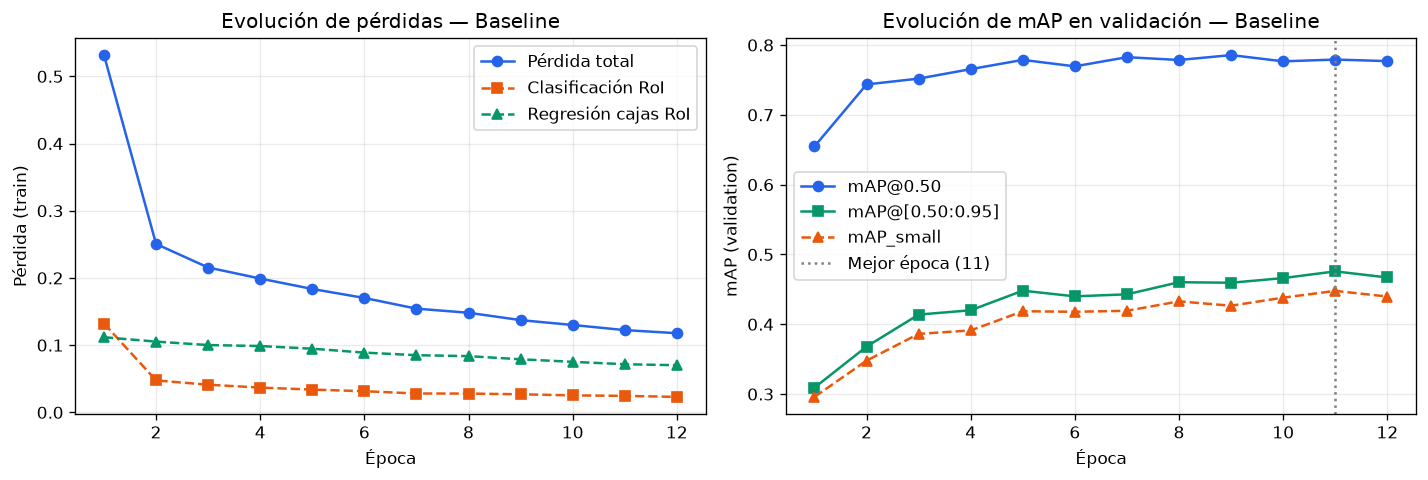

In [3]:
# Curvas de entrenamiento y validación del Baseline
hist_base = leer_json(EXPERIMENTOS[NOMBRE_BASELINE]["dir"] / "historial.json")
if hist_base:
    epocas = [h["epoca"] for h in hist_base]
    loss_tot = [h["perdidas_train"]["total"] for h in hist_base]
    loss_cls = [h["perdidas_train"]["loss_classifier"] for h in hist_base]
    loss_box = [h["perdidas_train"]["loss_box_reg"] for h in hist_base]
    val_map = [h["metricas_val"]["map"] for h in hist_base]
    val_map50 = [h["metricas_val"]["map_50"] for h in hist_base]
    val_small = [h["metricas_val"]["map_small"] for h in hist_base]

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.1))

    axes[0].plot(epocas, loss_tot, marker="o", color="#2563EB", label="Pérdida total")
    axes[0].plot(epocas, loss_cls, marker="s", linestyle="--", color="#EA580C", label="Clasificación RoI")
    axes[0].plot(epocas, loss_box, marker="^", linestyle="--", color="#059669", label="Regresión cajas RoI")
    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Pérdida (train)")
    axes[0].set_title("Evolución de pérdidas — Baseline")
    axes[0].legend()

    axes[1].plot(epocas, val_map50, marker="o", color="#2563EB", label="mAP@0.50")
    axes[1].plot(epocas, val_map, marker="s", color="#059669", label="mAP@[0.50:0.95]")
    axes[1].plot(epocas, val_small, marker="^", linestyle="--", color="#EA580C", label="mAP_small")
    mejor_idx = int(np.argmax(val_map))
    axes[1].axvline(epocas[mejor_idx], color="gray", linestyle=":", label=f"Mejor época ({epocas[mejor_idx]})")
    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("mAP (validation)")
    axes[1].set_title("Evolución de mAP en validación — Baseline")
    axes[1].legend()

    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "02_baseline_curvas_entrenamiento.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

=== Baseline en validation (mejor época = 11) ===
mAP@[0.50:0.95]: 0.4755 | mAP@0.50: 0.7791 | mAP@0.75: 0.4890
mAP_small:       0.4471 | mAP_medium: 0.5560 | mAP_large: 0.6318
Latencia:        105.9 ms/img (9.44 FPS)


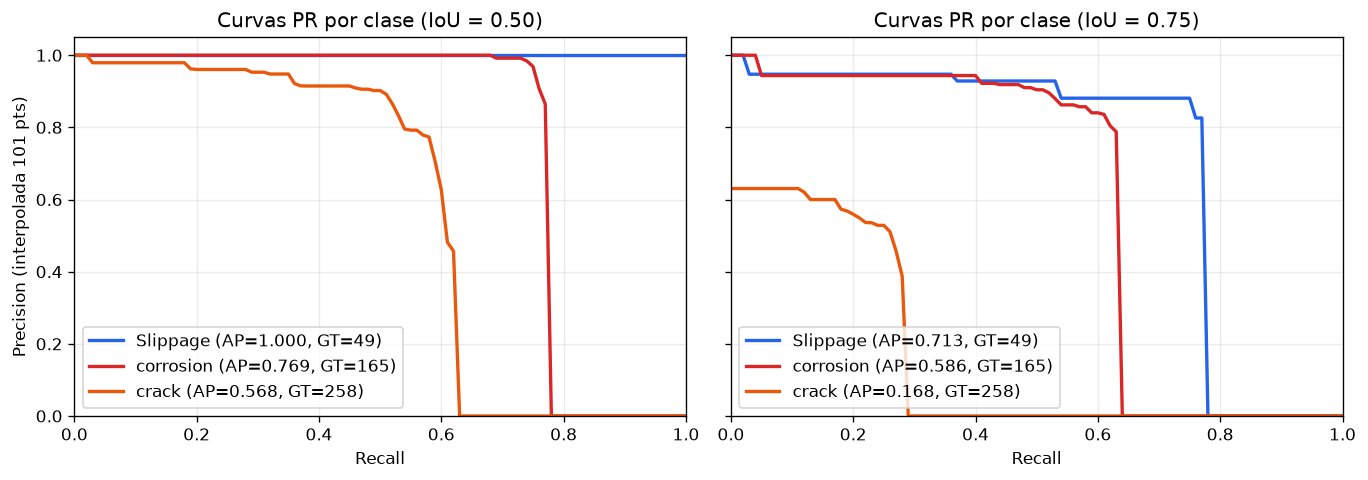

In [4]:
# Métricas y curvas Precisión-Recall (PR) del Baseline en validación
m_base = cargar_metricas(EXPERIMENTOS[NOMBRE_BASELINE]["dir"], "validation")
if m_base and 'curvas_pr_50' in m_base and 'curvas_pr_75' in m_base:
    tiempos_base = m_base["tiempos"]

    print("=== Baseline en validation (mejor época = 11) ===")
    print(f"mAP@[0.50:0.95]: {m_base['map']:.4f} | mAP@0.50: {m_base['map_50']:.4f} | mAP@0.75: {m_base['map_75']:.4f}")
    print(f"mAP_small:       {m_base['map_small']:.4f} | mAP_medium: {m_base['map_medium']:.4f} | mAP_large: {m_base['map_large']:.4f}")
    print(f"Latencia:        {tiempos_base['ms_por_imagen']:.1f} ms/img ({tiempos_base['fps']:.2f} FPS)")

    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True)
    for ax, clave_pr, titulo in [
        (axes[0], "curvas_pr_50", "Curvas PR por clase (IoU = 0.50)"),
        (axes[1], "curvas_pr_75", "Curvas PR por clase (IoU = 0.75)"),
    ]:
        curvas = m_base[clave_pr]
        for id_c, nombre_c in NOMBRES_CLASES.items():
            c = curvas[nombre_c]
            ax.plot(
                c["recall"],
                c["precision_interp"],
                linewidth=2.0,
                color=COLORES_CLASE[id_c],
                label=f"{nombre_c} (AP={c['ap']:.3f}, GT={c['n_gt']})",
            )
        ax.set_xlim(0, 1.0)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Recall")
        ax.set_title(titulo)
        ax.legend(loc="lower left")

    axes[0].set_ylabel("Precision (interpolada 101 pts)")
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "03_baseline_curvas_pr_validation.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

**Lectura rápida del Baseline:**
- Converge de forma estable (mejor época 11 con `mAP@[0.50:0.95] = 0.4755`, `mAP@0.50 = 0.7791`, `105,9 ms/img` en validación / `118,9 ms/img` en test).
- **`Slippage`** se detecta con altísima fiabilidad (`AP@0.50 = 1.000`, `AP@[0.50:0.95] = 0.669`), ya que son regiones más compactas y bien delimitadas.
- **`corrosion`** alcanza un rendimiento intermedio (`AP@0.50 = 0.769`, `AP = 0.499`), mientras que **`crack`** es el principal cuello de botella (`AP@0.50 = 0.568`, `AP = 0.259`) por ser grietas finas, alargadas y mayoritariamente en el rango `small`.

---
## 3. Estrategias de mejora propuestas

Cada estrategia parte de una hipótesis técnica concreta derivada del análisis del dataset y del comportamiento del baseline. El baseline y las variantes comparables usan **12 épocas**, semilla 42 y el mismo reparto. La variante a 960 px se repite desde COCO a 20 épocas con el calendario coseno ajustado. Las decisiones de entrenamiento e inferencia se toman en validación.

| Estrategia | Línea de mejora (Guion) | Hipótesis técnica y modificación aplicada |
|---|---|---|
| **E1** | Aumento de datos | Los defectos son invariantes a volteos H/V y sufren cambios de iluminación; recortes aleatorios con zoom (`0.65–0.95`) amplían el 85,2 % de objetos pequeños. Se añade `vflip`, recorte con zoom y `ColorJitter` (12 épocas). |
| **E2** | Transfer learning | Congelar el backbone 2 épocas evita distorsionar los filtros COCO al iniciar la cabeza nueva; luego se descongelan 3 bloques (`layer2–layer4`) con tasa diferenciada `0.1×` en el backbone (12 épocas). |
| **E3a** | Optimizador y scheduler | Comparar `SGD (lr=0.005, momentum=0.9)` + `MultiStepLR` (`[8, 11]`) frente a `AdamW + cosine` en un dataset reducido (`820` imágenes, 12 épocas). |
| **E3b** | Anchors y resolución | Reducir anchors a `[[16],[32],[64],[128],[256]]`, ampliar relaciones de aspecto a `[0.25, 0.5, 1.0, 2.0, 4.0]` y subir `min_size` de `800` a `960 px` para grietas finas y cajas `< 32²` (12 épocas). |
| **E3c** | SGD con coseno | Replica la configuración de optimización de RetinaNet con 12 épocas. Cambian el calendario y el `weight decay` frente a E3a. |
| **E3d** | Solo resolución | Sube de 800 a 960 px con anchors originales. Mantiene el protocolo del baseline a 12 épocas salvo la resolución y se repite aparte a 20 épocas. |
| **E4** | Funciones de pérdida | Sustituir Smooth L1 por **CIoU** (optimiza solapamiento, centro y aspecto) y ponderar la entropía cruzada `[1.0, 2.0, 1.0, 1.2]` para compensar `Slippage` y reforzar `crack` (12 épocas). |
| **E5a** | Post-procesado (NMS/Conf.) | Barrido en validación de `box_nms_thresh ∈ [0.30..0.60]` y `box_score_thresh ∈ [0.01..0.25]` sobre E1, ganador individual de la ronda original, sin reentrenar. |
| **E5b** | Test-Time Augmentation | WBF sobre E1 con `original + hflip + vflip` en la ronda original e IoU 0,55. En la ampliación se evalúan `original + hflip` sobre una nueva ejecución de E1. |
| **E6** | Ensemble WBF | Combinar mediante **WBF** con pesos iguales (`1:1:1`) las 3 variantes especializadas y complementarias de 12 épocas (**`E1 + E3b + E4`**). |

---
## 4. Evolución y comparativa cuantitativa en validación

### Ronda original de Faster R-CNN

Las primeras tablas y figuras recogen la ejecución original de Pablo. El baseline y los entrenamientos de esta ronda duraron 12 épocas. Las filas de NMS, TTA y E6 corresponden a inferencia. Las salidas guardadas permiten consultar esta referencia cuando los JSON originales no están en la copia local.

Los tiempos de la gráfica original son descriptivos de esa ejecución. Conviene distinguir las mediciones por lotes de los tiempos de inferencia por imagen y fusión al comparar configuraciones. La ampliación que sigue usa artefactos locales de otra ejecución.

,Experimento,Categoría,mAP@0.50:0.95,ΔmAP vs Base,mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,F1@0.5,ms/img,FPS
0,Baseline (Faster R-CNN v2),Baseline,0.4755,+0.0000,0.7791,0.4890,0.4471,0.6690,0.4989,0.2586,0.7538,105.9,9.4
1,E1: Data Augmentation,Aumento de datos,0.4854,+0.0099,0.8019,0.5055,0.4658,0.6686,0.5083,0.2794,0.7409,104.4,9.6
2,E2: Transfer Learning,Transfer learning,0.4649,-0.0106,0.7654,0.4952,0.4432,0.6766,0.4722,0.2459,0.7389,106.9,9.3
3,E3a: SGD + MultiStepLR,Optimizador,0.4485,-0.0270,0.7790,0.4769,0.4206,0.6444,0.4717,0.2293,0.7409,119.8,8.3
4,E3b: Anchors pequeños + 960 px,Anchors / Resolución,0.4739,-0.0016,0.7744,0.5331,0.4430,0.6697,0.4948,0.2574,0.7638,127.6,7.8
5,E4: Pérdida CIoU + CE ponderada,Funciones de pérdida,0.4725,-0.0030,0.7836,0.4887,0.4464,0.6788,0.4846,0.2542,0.7544,101.6,9.8
6,E5a: Ajuste NMS + Confianza,Post-procesado,0.4891,+0.0136,0.8074,0.5148,0.4684,0.6702,0.5142,0.2828,0.7216,101.7,9.8
7,E5b: TTA WBF (orig + hflip + vflip),Inferencia (TTA),0.4986,+0.0231,0.8082,0.5504,0.4763,0.6886,0.5298,0.2773,0.7653,337.5,3.0
8,E6: Ensemble WBF (E1 + E3b + E4),Ensemble WBF,0.5146,+0.0391,0.8153,0.5917,0.4877,0.7049,0.5383,0.3007,0.7784,356.8,2.8


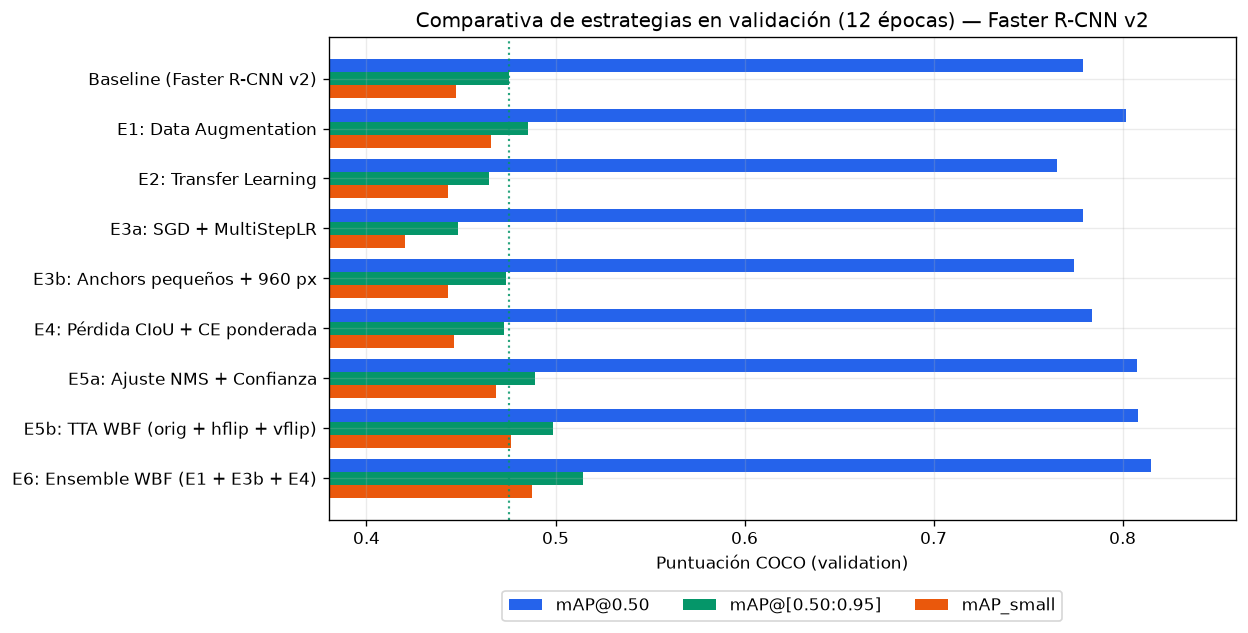

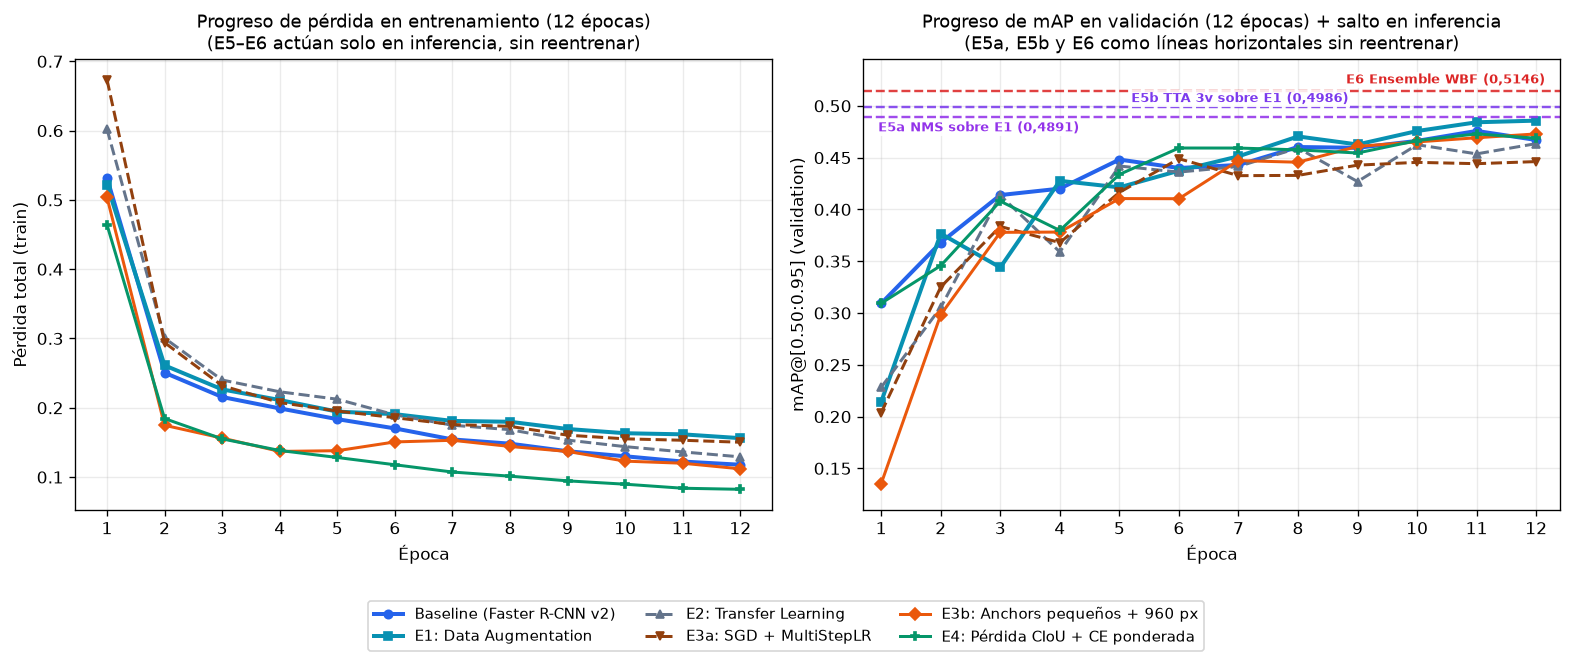

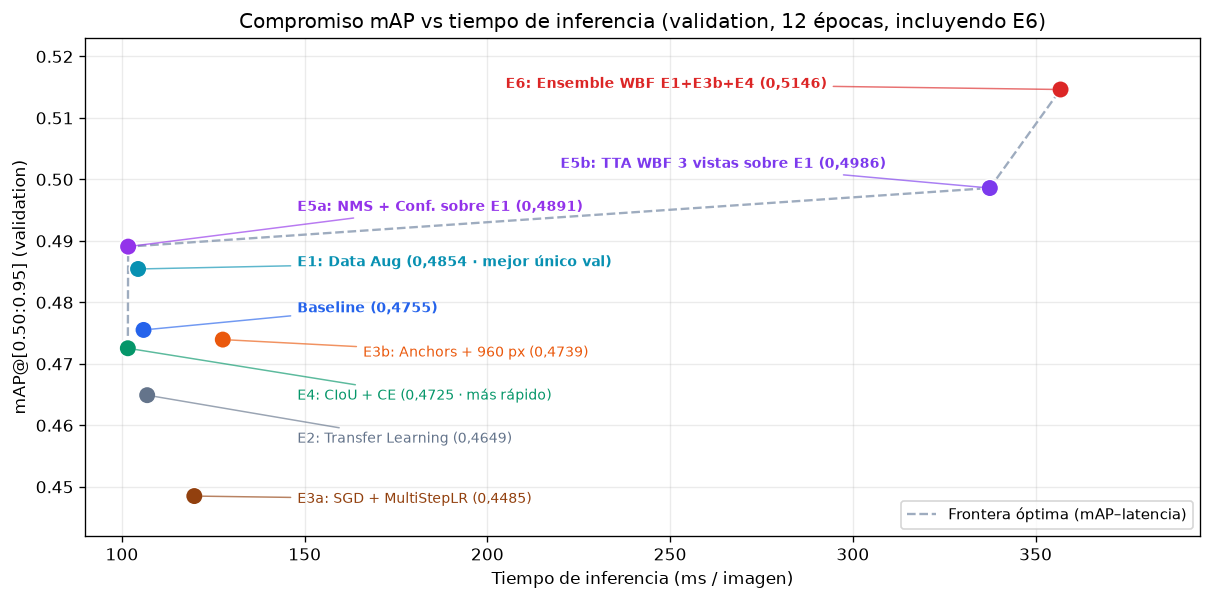

In [5]:
filas_comp = []
metricas_val = {}

for nombre_exp, meta in EXPERIMENTOS.items():
    m = cargar_metricas(meta["dir"], "validation")
    if m is None:
        continue
    if nombre_exp == "E1: Data Augmentation" and round(m["map"], 4) != 0.4854:
        # La repetición de E1 se analiza con las nuevas variantes.
        continue
    metricas_val[nombre_exp] = m
    pc = m.get("map_por_clase", {})
    t = m.get("tiempos", {})
    err = m.get("analisis_errores_05", {})
    filas_comp.append({
        "Experimento": nombre_exp,
        "Categoría": meta["categoria"],
        "mAP@0.50:0.95": m["map"],
        "mAP@0.50": m["map_50"],
        "mAP@0.75": m["map_75"],
        "mAP_small": m["map_small"],
        "AP Slippage": pc.get("Slippage", np.nan),
        "AP corrosion": pc.get("corrosion", np.nan),
        "AP crack": pc.get("crack", np.nan),
        "F1@0.5": err.get("f1", np.nan),
        "ms/img": t.get("ms_por_imagen", np.nan),
        "FPS": t.get("fps", np.nan),
    })

if NOMBRE_BASELINE in metricas_val:
    df_val = pd.DataFrame(filas_comp)
    ref_base = metricas_val[NOMBRE_BASELINE]["map"]
    df_val.insert(3, "ΔmAP vs Base", df_val["mAP@0.50:0.95"] - ref_base)

    display(
        df_val.style.format({
            "mAP@0.50:0.95": "{:.4f}",
            "ΔmAP vs Base": "{:+.4f}",
            "mAP@0.50": "{:.4f}",
            "mAP@0.75": "{:.4f}",
            "mAP_small": "{:.4f}",
            "AP Slippage": "{:.4f}",
            "AP corrosion": "{:.4f}",
            "AP crack": "{:.4f}",
            "F1@0.5": "{:.4f}",
            "ms/img": "{:.1f}",
            "FPS": "{:.1f}",
        }, na_rep="—")
    )

    # 1. Barras comparativas de mAP
    fig, ax = plt.subplots(figsize=(10.5, 5.4))
    y = np.arange(len(df_val))
    h = 0.26
    ax.barh(y - h, df_val["mAP@0.50"], height=h, label="mAP@0.50", color="#2563EB")
    ax.barh(y, df_val["mAP@0.50:0.95"], height=h, label="mAP@[0.50:0.95]", color="#059669")
    ax.barh(y + h, df_val["mAP_small"], height=h, label="mAP_small", color="#EA580C")
    ax.axvline(ref_base, color="#059669", linestyle=":", linewidth=1.3, alpha=0.85)
    ax.set_yticks(y)
    ax.set_yticklabels(df_val["Experimento"])
    ax.invert_yaxis()
    ax.set_xlim(0.38, 0.86)
    ax.set_xlabel("Puntuación COCO (validation)")
    ax.set_title("Comparativa de estrategias en validación (12 épocas) — Faster R-CNN v2")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.13))
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "04_comparativa_validacion.png", bbox_inches="tight")
    plt.show()

    # 1b. Evolución de la pérdida de entrenamiento y mAP de validación (todos a 12 épocas + líneas de referencia E5–E6)
    exps_entrenados = [
        (NOMBRE_BASELINE, "o", "-"),
        ("E1: Data Augmentation", "s", "-"),
        ("E2: Transfer Learning", "^", "--"),
        ("E3a: SGD + MultiStepLR", "v", "--"),
        ("E3b: Anchors pequeños + 960 px", "D", "-"),
        ("E4: Pérdida CIoU + CE ponderada", "P", "-"),
    ]

    fig, axes = plt.subplots(1, 2, figsize=(13.2, 4.9))
    for nombre_e, mk, ls in exps_entrenados:
        if nombre_e not in metricas_val:
            continue
        hist_e = leer_json(EXPERIMENTOS[nombre_e]["dir"] / "historial.json")
        if not hist_e:
            continue
        eps = [h["epoca"] for h in hist_e]
        losses = [h["perdidas_train"]["total"] for h in hist_e]
        maps = [h["metricas_val"]["map"] for h in hist_e]
        color_e = COLORES_EXP[nombre_e]
        lw = 2.4 if nombre_e in (NOMBRE_BASELINE, "E1: Data Augmentation") else 1.8
        axes[0].plot(eps, losses, marker=mk, linestyle=ls, color=color_e, linewidth=lw, markersize=5, label=nombre_e)
        axes[1].plot(eps, maps, marker=mk, linestyle=ls, color=color_e, linewidth=lw, markersize=5, label=nombre_e)

    axes[0].set_xlabel("Época")
    axes[0].set_ylabel("Pérdida total (train)")
    axes[0].set_title("Progreso de pérdida en entrenamiento (12 épocas)\n(E5–E6 actúan solo en inferencia, sin reentrenar)", fontsize=10.5)
    axes[0].set_xticks(range(1, 13))

    # Líneas de referencia en inferencia (sin entrenamiento): E5a, E5b, E6 (escalonadas sin solape)
    exps_inferencia = [
        ("E5a: Ajuste NMS + Confianza", "E5a NMS sobre E1 (0,4891)", 0.95, -0.004, "left", "top"),
        ("E5b: TTA WBF (orig + hflip + vflip)", "E5b TTA 3v sobre E1 (0,4986)", 5.2, 0.002, "left", "bottom"),
        ("E6: Ensemble WBF (E1 + E3b + E4)", "E6 Ensemble WBF (0,5146)", 12.15, 0.004, "right", "bottom"),
    ]
    for nombre_inf, etq_inf, x_txt, dy_txt, ha_txt, va_txt in exps_inferencia:
        if nombre_inf in metricas_val:
            val_m = metricas_val[nombre_inf]["map"]
            col_inf = COLORES_EXP[nombre_inf]
            axes[1].axhline(val_m, color=col_inf, linestyle="--", linewidth=1.45, alpha=0.88)
            axes[1].text(
                x_txt, val_m + dy_txt, etq_inf,
                color=col_inf, fontsize=7.9, fontweight="bold", ha=ha_txt, va=va_txt,
                bbox={"facecolor": "white", "alpha": 0.88, "edgecolor": "none", "pad": 1.1},
            )

    axes[1].set_xlabel("Época")
    axes[1].set_ylabel("mAP@[0.50:0.95] (validation)")
    axes[1].set_title("Progreso de mAP en validación (12 épocas) + salto en inferencia\n(E5a, E5b y E6 como líneas horizontales sin reentrenar)", fontsize=10.5)
    axes[1].set_xticks(range(1, 13))
    axes[1].set_xlim(0.7, 12.4)
    axes[1].set_ylim(0.11, 0.545)

    handles, labels = axes[1].get_legend_handles_labels()
    fig.legend(handles, labels, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8.8)
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "04b_curvas_entrenamiento_mejoras.png", bbox_inches="tight")
    plt.show()

    # 2. Compromiso mAP vs latencia (colores unificados e incluyendo E6)
    df_lat = df_val.dropna(subset=["ms/img"]).copy()
    fig, ax = plt.subplots(figsize=(10.2, 5.1))

    # Frontera de Pareto (máximo mAP acumulado ordenando por latencia creciente)
    df_ord = df_lat.sort_values("ms/img")
    pareto_x, pareto_y = [], []
    max_y = -1.0
    for _, fila in df_ord.iterrows():
        if fila["mAP@0.50:0.95"] > max_y:
            max_y = fila["mAP@0.50:0.95"]
            pareto_x.append(fila["ms/img"])
            pareto_y.append(max_y)
    ax.plot(pareto_x, pareto_y, linestyle="--", color="#94A3B8", linewidth=1.4, alpha=0.9, zorder=2, label="Frontera óptima (mAP–latencia)")

    colores_pts = [COLORES_EXP.get(e, "#2563EB") for e in df_lat["Experimento"]]
    ax.scatter(df_lat["ms/img"], df_lat["mAP@0.50:0.95"], s=110, c=colores_pts, edgecolors="white", linewidth=0.9, zorder=3)

    # Posiciones absolutas limpias (xytext en coordenadas de datos) para evitar cualquier solape en el grupo rápido (101–128 ms)
    pos_etiquetas = {
        "E5a: Ajuste NMS + Confianza": ("E5a: NMS + Conf. sobre E1 (0,4891)", (148, 0.4955)),
        "E1: Data Augmentation": ("E1: Data Aug (0,4854 · mejor único val)", (148, 0.4865)),
        NOMBRE_BASELINE: ("Baseline (0,4755)", (148, 0.4790)),
        "E3b: Anchors pequeños + 960 px": ("E3b: Anchors + 960 px (0,4739)", (166, 0.4718)),
        "E4: Pérdida CIoU + CE ponderada": ("E4: CIoU + CE (0,4725 · más rápido)", (148, 0.4648)),
        "E2: Transfer Learning": ("E2: Transfer Learning (0,4649)", (148, 0.4578)),
        "E3a: SGD + MultiStepLR": ("E3a: SGD + MultiStepLR (0,4485)", (148, 0.4480)),
        "E5b: TTA WBF (orig + hflip + vflip)": ("E5b: TTA WBF 3 vistas sobre E1 (0,4986)", (220, 0.5025)),
        "E6: Ensemble WBF (E1 + E3b + E4)": ("E6: Ensemble WBF E1+E3b+E4 (0,5146)", (205, 0.5155)),
    }
    destacados = {
        NOMBRE_BASELINE,
        "E1: Data Augmentation",
        "E5a: Ajuste NMS + Confianza",
        "E5b: TTA WBF (orig + hflip + vflip)",
        "E6: Ensemble WBF (E1 + E3b + E4)",
    }
    for _, fila in df_lat.iterrows():
        nombre_e = fila["Experimento"]
        x_p, y_p = fila["ms/img"], fila["mAP@0.50:0.95"]
        etq, (x_t, y_t) = pos_etiquetas.get(nombre_e, (nombre_e, (x_p + 15, y_p)))
        col_e = COLORES_EXP.get(nombre_e, "#334155")
        ax.annotate(
            etq,
            xy=(x_p, y_p),
            xytext=(x_t, y_t),
            fontsize=8.5,
            fontweight="bold" if nombre_e in destacados else "normal",
            color=col_e,
            va="center",
            arrowprops={"arrowstyle": "-", "color": col_e, "lw": 0.9, "alpha": 0.65, "shrinkA": 2, "shrinkB": 5},
        )

    ax.set_xlim(90, 395)
    ax.set_ylim(0.442, 0.523)
    ax.set_xlabel("Tiempo de inferencia (ms / imagen)")
    ax.set_ylabel("mAP@[0.50:0.95] (validation)")
    ax.set_title("Compromiso mAP vs tiempo de inferencia (validation, 12 épocas, incluyendo E6)")
    ax.legend(loc="lower right", fontsize=8.8)
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "05_tradeoff_latencia_validation.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

Mejor configuración en validación: E6: Ensemble WBF (E1 + E3b + E4) (mAP=0.5146)


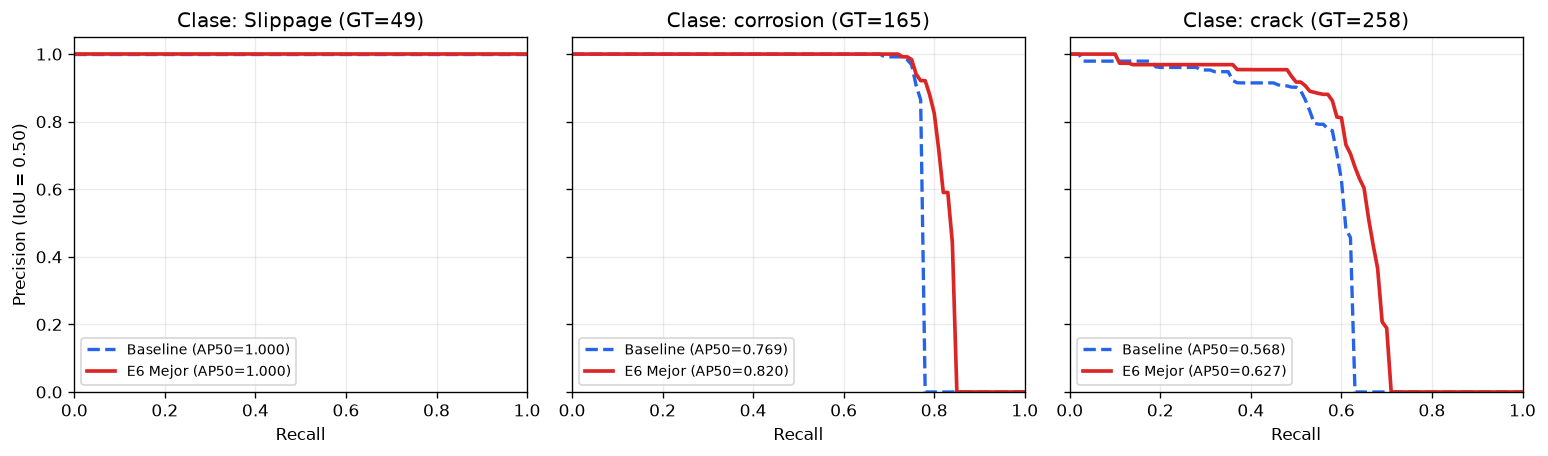

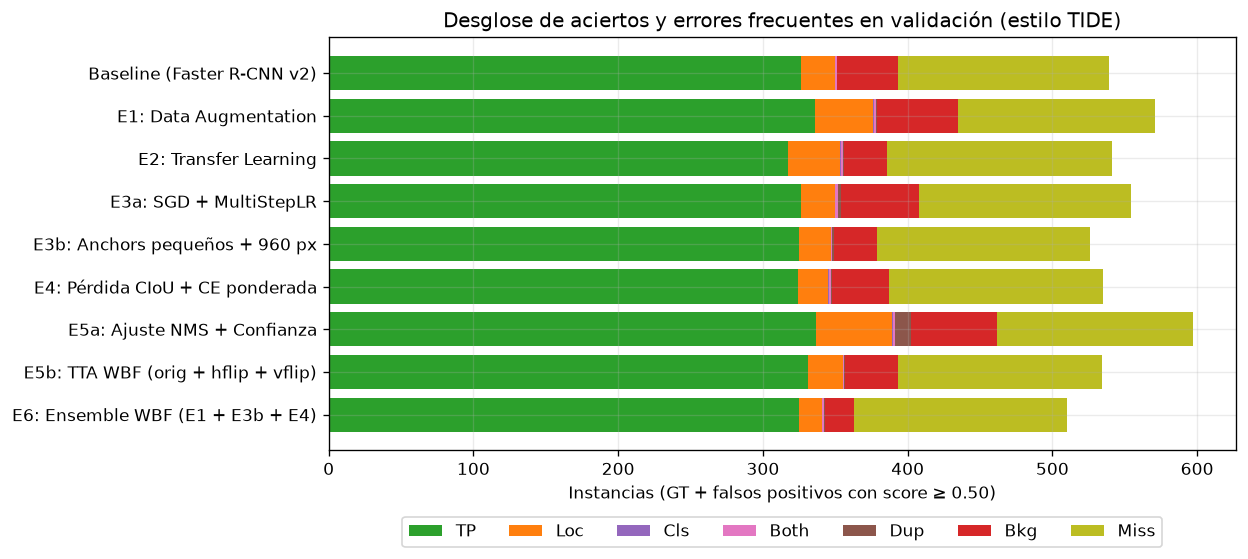

In [6]:
# Curvas PR y errores de la ronda original.
nombre_mejor = "E6: Ensemble WBF (E1 + E3b + E4)"
if all(nombre in metricas_val for nombre in (NOMBRE_BASELINE, nombre_mejor)):
    print(f"Mejor configuración en validación: {nombre_mejor} (mAP={metricas_val[nombre_mejor]['map']:.4f})")

    # 1. Curvas PR por clase: Baseline vs Mejor modelo
    fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.9), sharey=True)
    for ax, (id_c, nombre_c) in zip(axes, NOMBRES_CLASES.items()):
        c_base = metricas_val[NOMBRE_BASELINE]["curvas_pr_50"][nombre_c]
        c_best = metricas_val[nombre_mejor]["curvas_pr_50"][nombre_c]
        ax.plot(c_base["recall"], c_base["precision_interp"], "--", color=COLORES_EXP[NOMBRE_BASELINE], linewidth=2.0, label=f"Baseline (AP50={c_base['ap']:.3f})")
        ax.plot(c_best["recall"], c_best["precision_interp"], "-", color=COLORES_EXP[nombre_mejor], linewidth=2.2, label=f"E6 Mejor (AP50={c_best['ap']:.3f})")
        ax.set_xlim(0, 1)
        ax.set_ylim(0, 1.05)
        ax.set_xlabel("Recall")
        ax.set_title(f"Clase: {nombre_c} (GT={c_base['n_gt']})")
        ax.legend(loc="lower left", fontsize=8.5)
    axes[0].set_ylabel("Precision (IoU = 0.50)")
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "06_curvas_pr_comparativa_validation.png", bbox_inches="tight")
    plt.show()

    # 2. Desglose de aciertos y tipos de error (estilo TIDE, score >= 0.50)
    claves_err = ["TP", "Loc", "Cls", "Both", "Dup", "Bkg", "Miss"]
    colores_err = {
        "TP": "#2ca02c",
        "Loc": "#ff7f0e",
        "Cls": "#9467bd",
        "Both": "#e377c2",
        "Dup": "#8c564b",
        "Bkg": "#d62728",
        "Miss": "#bcbd22",
    }
    exps_err = list(metricas_val.keys())
    fig, ax = plt.subplots(figsize=(10.5, 4.8))
    y = np.arange(len(exps_err))
    izq = np.zeros(len(exps_err))
    for clave in claves_err:
        vals = np.array([metricas_val[e]["analisis_errores_05"][clave] for e in exps_err])
        ax.barh(y, vals, left=izq, label=clave, color=colores_err[clave])
        izq += vals
    ax.set_yticks(y)
    ax.set_yticklabels(exps_err)
    ax.invert_yaxis()
    ax.set_xlabel("Instancias (GT + falsos positivos con score ≥ 0.50)")
    ax.set_title("Desglose de aciertos y errores frecuentes en validación (estilo TIDE)")
    ax.legend(ncol=7, loc="upper center", bbox_to_anchor=(0.5, -0.14))
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "07_analisis_errores_validacion.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

### Lectura de la ronda original (12 épocas)

- **E1 · Aumento de datos.** Fue el mejor checkpoint individual de esta ronda con 0,4854 de mAP, frente a 0,4755 del baseline. También elevó el mAP_small de 0,4471 a 0,4658 y el AP de `crack` de 0,2586 a 0,2794.
- **E2 · Descongelado y tasa diferenciada.** Obtuvo 0,4649 de mAP y 0,4952 a IoU 0,75. El resultado corresponde al conjunto de cambios de congelación y tasa de aprendizaje.
- **E3a y E3b · Optimización y geometría.** SGD + MultiStepLR obtuvo 0,4485 de mAP. Con anchors ajustados y 960 px, E3b alcanzó 0,5331 de mAP@0,75 y 0,7638 de F1, aunque su mAP global fue 0,4739. La ampliación aísla el aumento de resolución con anchors originales.
- **E4 · CIoU y entropía cruzada ponderada.** Quedó en 0,4725 de mAP y obtuvo el mayor AP individual de `Slippage` de la ronda (0,6788).
- **E5a, E5b y E6 · Inferencia.** Sobre el E1 original, NMS ajustado obtuvo 0,4891 de mAP y el TTA de tres vistas 0,4986. E6 (WBF de E1, E3b y E4) obtuvo 0,5146, el mejor resultado global de validación.

### Ampliación para comparar con RetinaNet

E3c replica la receta SGD + coseno. E3d mide el aumento de resolución con anchors originales, primero a 12 épocas y después a 20 épocas desde COCO. La nueva ejecución de E1 se incluye porque su checkpoint se usó en la prueba de TTA de dos vistas. La tabla muestra tiempos por lotes de cuatro de esta tanda. Para comparar velocidad con la ronda original haría falta un cronometraje común.

,Configuración,Épocas,mAP@[0.50:0.95],mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,F1@0.5,ms/img (lote 4)
0,E1 · Aumentos (repetición),12,0.4685,0.7909,0.5096,0.4445,0.6446,0.4963,0.2646,0.7269,39.62
1,E3c · SGD + coseno,12,0.4475,0.7758,0.4528,0.4240,0.6259,0.4667,0.2497,0.7250,37.96
2,"E3d · 960 px, anchors originales",12,0.4836,0.7698,0.5438,0.4550,0.6971,0.4929,0.2608,0.7407,48.55
3,"E3d · 960 px, anchors originales (20 épocas)",20,0.4868,0.7786,0.5534,0.4576,0.6657,0.5087,0.2860,0.7462,49.19


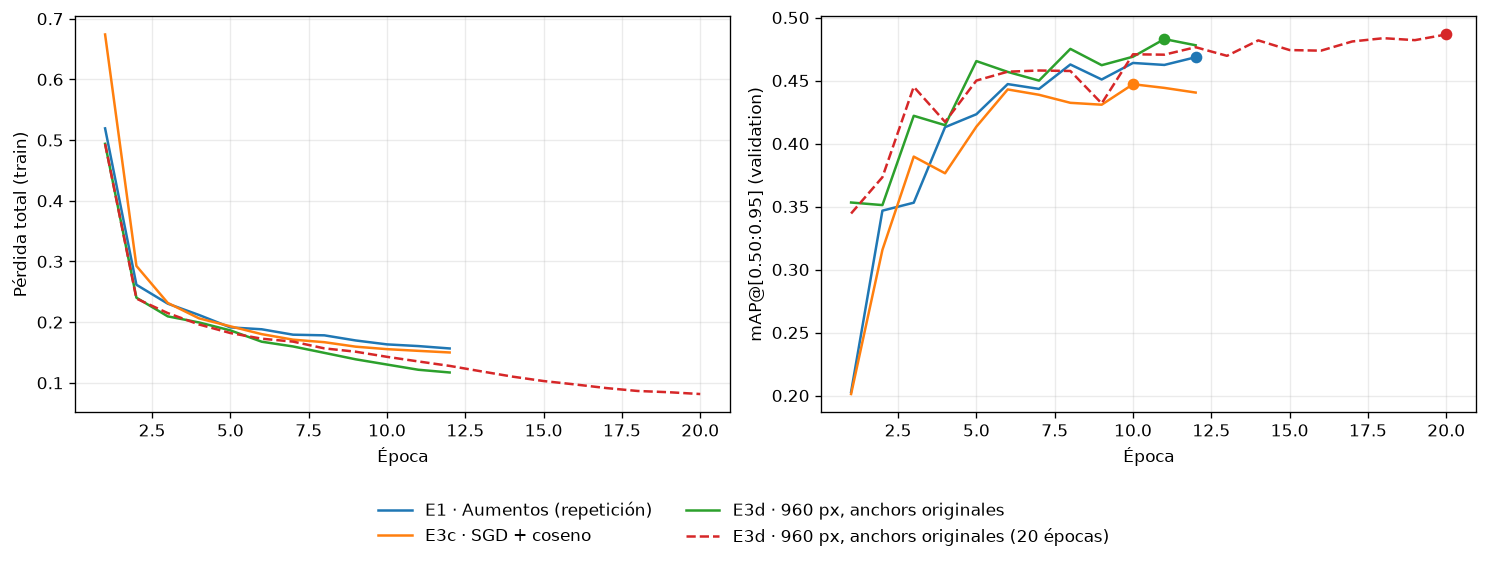

In [9]:
experimentos_ampliacion = {
    "E1 · Aumentos (repetición)": ("exp01_data_augmentation", 12),
    "E3c · SGD + coseno": ("faster_rcnn_sgd_cosine", 12),
    "E3d · 960 px, anchors originales": ("faster_rcnn_resolucion_12ep", 12),
    "E3d · 960 px, anchors originales (20 épocas)": ("faster_rcnn_resolucion_20ep", 20),
}
filas_ampliacion = []
curvas_ampliacion = {}
for nombre, (carpeta, presupuesto) in experimentos_ampliacion.items():
    directorio = DIR_RESULTADOS / carpeta
    m = cargar_metricas(directorio)
    historial = leer_json(directorio / "historial.json")
    if historial:
        curvas_ampliacion[nombre] = historial
    if m is None:
        continue
    ap_clase = m.get("map_por_clase", {})
    filas_ampliacion.append({
        "Configuración": nombre,
        "Épocas": presupuesto,
        "mAP@[0.50:0.95]": m["map"],
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP@0.75": m.get("map_75", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "AP Slippage": ap_clase.get("Slippage", np.nan),
        "AP corrosion": ap_clase.get("corrosion", np.nan),
        "AP crack": ap_clase.get("crack", np.nan),
        "F1@0.5": m.get("analisis_errores_05", {}).get("f1", np.nan),
        "ms/img (lote 4)": m.get("tiempos", {}).get("ms_por_imagen", np.nan),
    })

if filas_ampliacion:
    df_ampliacion = pd.DataFrame(filas_ampliacion)
    display(df_ampliacion.style.format({"ms/img (lote 4)": "{:.2f}"}, precision=4, na_rep="—"))
else:
    print("Faltan las métricas de los experimentos cruzados.")

if curvas_ampliacion:
    fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.7), sharex=True)
    for nombre, historial in curvas_ampliacion.items():
        epocas = [registro["epoca"] for registro in historial]
        perdidas = [registro["perdidas_train"]["total"] for registro in historial]
        m_ap = [registro["metricas_val"]["map"] for registro in historial]
        mejor = int(np.argmax(m_ap))
        estilo = "--" if experimentos_ampliacion[nombre][1] == 20 else "-"
        linea, = axes[0].plot(epocas, perdidas, linestyle=estilo, label=nombre)
        axes[1].plot(epocas, m_ap, linestyle=estilo, color=linea.get_color())
        axes[1].scatter(epocas[mejor], m_ap[mejor], color=linea.get_color(), zorder=3)
    axes[0].set_ylabel("Pérdida total (train)")
    axes[1].set_ylabel("mAP@[0.50:0.95] (validation)")
    for ax in axes:
        ax.set_xlabel("Época")
    handles, etiquetas = axes[0].get_legend_handles_labels()
    fig.legend(handles, etiquetas, loc="lower center", ncol=2, frameon=False)
    fig.tight_layout(rect=(0, 0.13, 1, 1))
    fig.savefig(DIR_FIGURAS / "11_curvas_experimentos_cruzados.png", bbox_inches="tight")
    plt.show()

- **Resolución a 12 épocas.** E3d alcanza 0,4836 de mAP y 0,5438 de mAP@0,75. Frente al baseline original (0,4755 y 0,4890), mejora en ambas métricas. Frente a E3b (960 px y anchors ajustados, 0,4739 y 0,5331), la variante con anchors originales obtuvo mejores valores en esta comparación de ejecuciones.
- **Resolución a 20 épocas.** E3d sube a 0,4868 de mAP y 0,5534 a IoU 0,75. El mejor checkpoint se obtuvo en la época 20. Supera por 0,32 puntos porcentuales a E3d a 12 épocas y obtiene el mayor mAP de los checkpoints individuales comparados. El E1 original sigue siendo el mejor individual de la ronda original y obtuvo 0,4854.
- **SGD + coseno.** E3c queda en 0,4475 de mAP, cerca de 0,4485 de E3a. Ambas recetas obtuvieron un mAP inferior al baseline AdamW.

**Comparación con RetinaNet a 12 épocas.** El aumento de 800 a 960 px con anchors originales elevó el mAP en ambos detectores. Frente a sus respectivos baselines registrados, pasó de 0,4755 a 0,4836 en Faster R-CNN y de 0,4319 a 0,4497 en RetinaNet. Son diferencias observadas en una ejecución por configuración.

---
## 5. Análisis cualitativo e inferencia con TTA

### Detecciones correctas y fallos frecuentes en la ronda original

Comparamos el baseline con E6, la configuración con mayor mAP global en validación. Las figuras usan estas convenciones.
- **Verde discontinuo:** *Ground Truth* (anotaciones reales).
- **Línea continua de color:** predicciones con `score ≥ 0.50` (`azul = Slippage`, `rojo = corrosion`, `naranja = crack`).

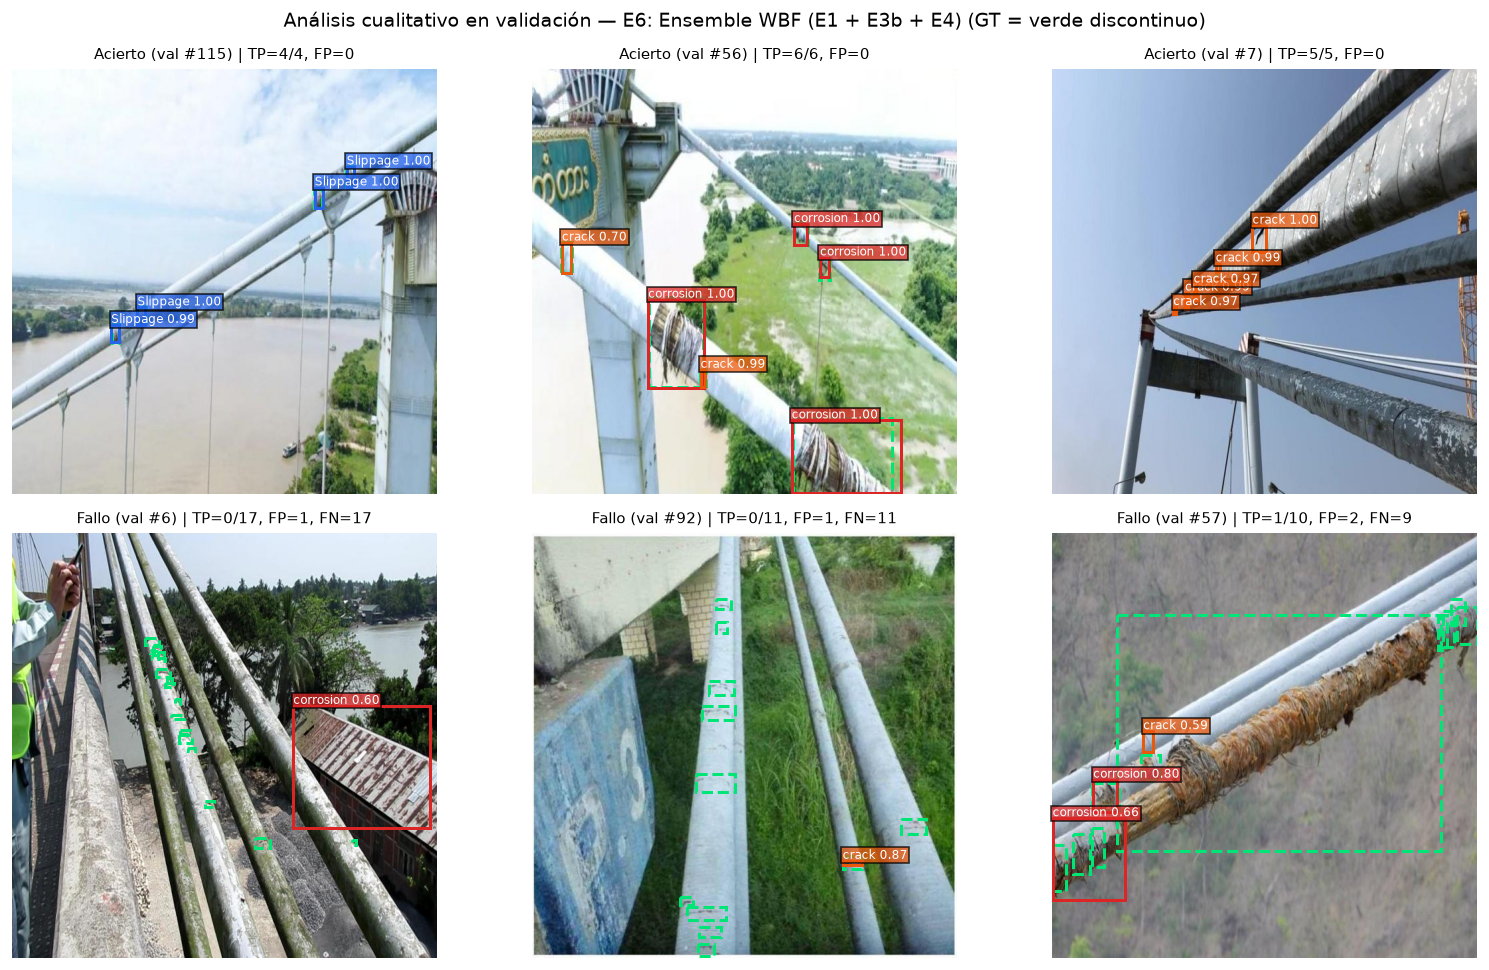

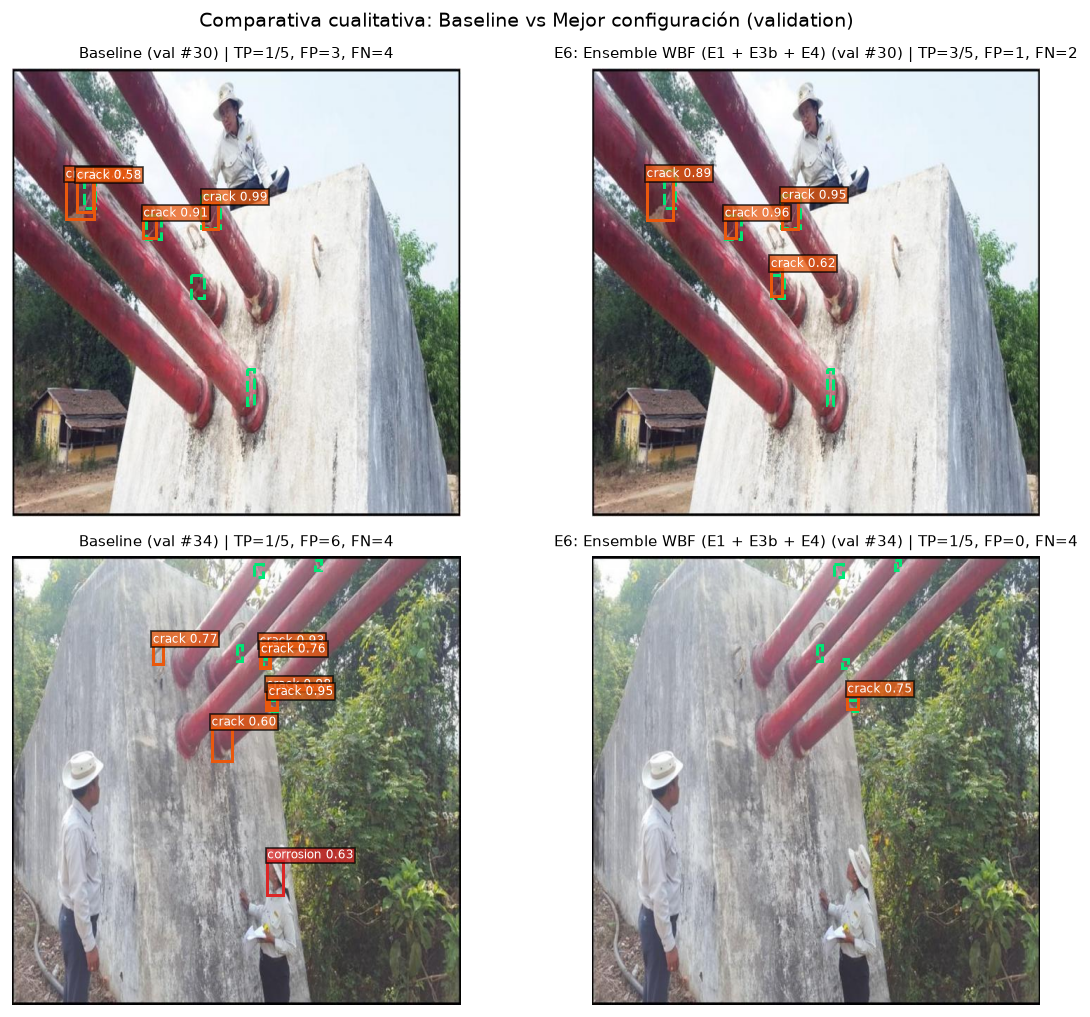

In [7]:
def dibujar_detecciones(ax, imagen_tensor, gt, pred, titulo="", score_thr=0.50):
    ax.imshow(imagen_tensor.permute(1, 2, 0).numpy())
    for caja in gt["boxes"].numpy():
        x1, y1, x2, y2 = caja
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="#00e676", linewidth=1.8, linestyle="--"))
    for caja, score, etq in zip(pred["boxes"].numpy(), pred["scores"].numpy(), pred["labels"].numpy()):
        if score < score_thr:
            continue
        x1, y1, x2, y2 = caja
        color = COLORES_CLASE.get(int(etq), "yellow")
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, linewidth=1.8))
        ax.text(
            x1, max(0, y1 - 3), f"{NOMBRES_CLASES.get(int(etq), etq)} {score:.2f}",
            color="white", fontsize=7, bbox={"facecolor": color, "alpha": 0.75, "pad": 1},
        )
    ax.set_title(titulo, fontsize=9)
    ax.axis("off")


def evaluar_imagenes(ds, preds, score_thr=0.50):
    resumenes = []
    for idx in range(len(ds)):
        _, gt = ds[idx]
        pred = preds[idx]
        cajas_gt, etq_gt = gt["boxes"].numpy(), gt["labels"].numpy()
        mask = pred["scores"].numpy() >= score_thr
        cajas_p, etq_p = pred["boxes"].numpy()[mask], pred["labels"].numpy()[mask]
        tp = 0
        usado = np.zeros(len(cajas_gt), dtype=bool)
        if len(cajas_gt) > 0 and len(cajas_p) > 0:
            ious = _iou_entre_cajas(cajas_p, cajas_gt)
            for i in range(len(cajas_p)):
                for j in range(len(cajas_gt)):
                    if not usado[j] and etq_p[i] == etq_gt[j] and ious[i, j] >= 0.5:
                        tp += 1
                        usado[j] = True
                        break
        clases_gt = set(int(c) for c in etq_gt)
        resumenes.append({"idx": idx, "n_gt": len(cajas_gt), "tp": tp, "fp": len(cajas_p) - tp, "fn": len(cajas_gt) - tp, "clases": clases_gt})
    return resumenes


ruta_preds_base = EXPERIMENTOS[NOMBRE_BASELINE]["dir"] / "predicciones_validation.json"
ruta_preds_best = EXPERIMENTOS[nombre_mejor]["dir"] / "predicciones_validation.json"
if not ruta_preds_best.is_file():
    ruta_preds_best = DIR_RESULTADOS / "faster_rcnn_pablo" / "ensemble_e6" / "predicciones_validation.json"

if ruta_preds_base.is_file() and ruta_preds_best.is_file():
    ds_val = CorrosionDataset("validation")
    preds_base = cargar_predicciones(ruta_preds_base)
    preds_best = cargar_predicciones(ruta_preds_best)

    stats_base = evaluar_imagenes(ds_val, preds_base, score_thr=0.50)
    stats_best = evaluar_imagenes(ds_val, preds_best, score_thr=0.50)

    # 1. Top 3 aciertos diversos (uno por clase: Slippage, corrosion, crack) y Top 3 fallos frecuentes
    aciertos = []
    usados_acierto = set()
    for id_clase in (1, 2, 3):
        cands = [s for s in stats_best if s["n_gt"] >= 2 and id_clase in s["clases"] and s["idx"] not in usados_acierto]
        cands.sort(key=lambda s: (-s["tp"] / s["n_gt"], s["fp"] + s["fn"], -s["tp"]))
        if cands:
            aciertos.append(cands[0])
            usados_acierto.add(cands[0]["idx"])
    fallos = sorted([s for s in stats_best if s["n_gt"] >= 1], key=lambda s: -(s["fn"] + s["fp"]))[:3]

    fig, axes = plt.subplots(2, 3, figsize=(13.2, 8.2))
    for col, s in enumerate(aciertos):
        img, gt = ds_val[s["idx"]]
        dibujar_detecciones(axes[0, col], img, gt, preds_best[s["idx"]], titulo=f"Acierto (val #{s['idx']}) | TP={s['tp']}/{s['n_gt']}, FP={s['fp']}")
    for col, s in enumerate(fallos):
        img, gt = ds_val[s["idx"]]
        dibujar_detecciones(axes[1, col], img, gt, preds_best[s["idx"]], titulo=f"Fallo (val #{s['idx']}) | TP={s['tp']}/{s['n_gt']}, FP={s['fp']}, FN={s['fn']}")
    fig.suptitle(f"Análisis cualitativo en validación — {nombre_mejor} (GT = verde discontinuo)", fontsize=11.5)
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "08_analisis_cualitativo_validation.png", bbox_inches="tight")
    plt.show()

    # 2. Comparativa visual directa: Baseline vs Mejor configuración (2 imágenes donde mejora sin perder TP)
    mejoras = sorted(
        [i for i in range(len(ds_val)) if stats_best[i]["tp"] >= stats_base[i]["tp"] and (stats_best[i]["tp"] > stats_base[i]["tp"] or stats_best[i]["fp"] < stats_base[i]["fp"])],
        key=lambda i: (
            (stats_best[i]["tp"] - stats_base[i]["tp"]) * 2 + (stats_base[i]["fp"] - stats_best[i]["fp"]),
            stats_best[i]["tp"],
        ),
        reverse=True,
    )[:2]

    fig, axes = plt.subplots(2, 2, figsize=(10.5, 8.6))
    for fila, idx in enumerate(mejoras):
        img, gt = ds_val[idx]
        sb, sm = stats_base[idx], stats_best[idx]
        dibujar_detecciones(axes[fila, 0], img, gt, preds_base[idx], titulo=f"Baseline (val #{idx}) | TP={sb['tp']}/{sb['n_gt']}, FP={sb['fp']}, FN={sb['fn']}")
        dibujar_detecciones(axes[fila, 1], img, gt, preds_best[idx], titulo=f"{nombre_mejor} (val #{idx}) | TP={sm['tp']}/{sm['n_gt']}, FP={sm['fp']}, FN={sm['fn']}")
    fig.suptitle("Comparativa cualitativa: Baseline vs Mejor configuración (validation)", fontsize=11.5)
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "09_comparativa_base_vs_mejor.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

**Patrones observados en el análisis cualitativo:**
- **Aciertos consistentes:** los defectos `Slippage` y focos definidos de `corrosion` se localizan con gran ajuste y alta confianza (`> 0.90`), sin confusión entre clases (`Cls = 0` en el baseline y en E6).
- **Fallos frecuentes (coherentes con el desglose TIDE):**
  1. **Falsos negativos (`Miss`) en `crack`:** grietas muy delgadas, con bajo contraste o densamente agrupadas en la misma superficie.
  2. **Falsos positivos de fondo (`Bkg`) y fragmentación (`Loc`):** sombras lineales, juntas de hormigón o manchas difusas de óxido donde el límite de la caja es ambiguo (a veces el detector predice una caja grande donde el *ground truth* anota varias pequeñas, o viceversa).
- **Mejora cualitativa:** en las imágenes seleccionadas, E6 recupera detecciones y elimina falsos positivos respecto al baseline.

### TTA de dos vistas sobre E1 reentrenado

La prueba cruzada fusiona la vista original y el volteo horizontal con WBF (IoU 0,55). La fila de una sola vista usa el mismo E1 reentrenado. El TTA de tres vistas de la ronda original (0,4986 de mAP) parte de otro checkpoint de E1. Su diferencia con 0,4821 incluye el cambio de checkpoint y el número de vistas.

In [10]:
variantes_e1 = {
    "E1 reentrenado · una vista": ("exp01_data_augmentation", "Lote de 4"),
    "E1 reentrenado · original + hflip": ("faster_rcnn_tta_2_vistas", "Imagen a imagen + WBF"),
}
filas_tta = []
for nombre, (carpeta, protocolo) in variantes_e1.items():
    m = cargar_metricas(DIR_RESULTADOS / carpeta)
    if m is None:
        continue
    if carpeta == "exp01_data_augmentation" and round(m["map"], 4) == 0.4854:
        print("Para emparejar con el TTA de esta tabla se necesita el E1 reentrenado (mAP 0,4685).")
        continue
    filas_tta.append({
        "Inferencia": nombre,
        "mAP@[0.50:0.95]": m["map"],
        "mAP@0.50": m.get("map_50", np.nan),
        "mAP@0.75": m.get("map_75", np.nan),
        "mAP_small": m.get("map_small", np.nan),
        "F1@0.5": m.get("analisis_errores_05", {}).get("f1", np.nan),
        "ms/imagen": m.get("tiempos", {}).get("ms_por_imagen", np.nan),
        "Protocolo": protocolo,
    })

if filas_tta:
    df_tta = pd.DataFrame(filas_tta)
    display(df_tta.style.format({"ms/imagen": "{:.2f}"}, precision=4, na_rep="—"))
else:
    print("Faltan las métricas guardadas para la comparación de dos vistas.")

,Inferencia,mAP@[0.50:0.95],mAP@0.50,mAP@0.75,mAP_small,F1@0.5,ms/imagen,Protocolo
0,E1 reentrenado · una vista,0.4685,0.7909,0.5096,0.4445,0.7269,39.62,Lote de 4
1,E1 reentrenado · original + hflip,0.4821,0.7842,0.5257,0.4577,0.7314,88.86,Imagen a imagen + WBF


Con el mismo checkpoint reentrenado, dos vistas elevan el mAP global de 0,4685 a 0,4821 y el mAP_small de 0,4445 a 0,4577. El mAP@0,50 baja de 0,7909 a 0,7842 y el mAP@0,75 sube de 0,5096 a 0,5257. La tabla indica los distintos protocolos de cronometraje de cada fila.

---
## 6. Ensemble WBF con RetinaNet v2

Combinamos el E6 de Faster R-CNN con las salidas de RetinaNet E2 de una y dos vistas, con WBF de pesos 1:1 e IoU 0,55. La fusión de dos vistas fue la mejor de las dos (0,5067 de mAP global en validación y 0,4657 en test). E6 solo conservó el mayor mAP global en ambos repartos (0,5146 y 0,4696). [Método y resultados de las fusiones](resultados_ensemble.ipynb)

---
## 7. Evaluación final en `test` (configuraciones seleccionadas en validación)

Esta sección recoge la evaluación original en **`test`** (304 imágenes, 1.282 objetos), realizada tras seleccionar configuraciones en validación. La evaluación adicional de E3d a 20 épocas aparece después de la tabla original. La selección de la ronda original fue la siguiente.
- **E1 (`Data Augmentation`):** ganador individual en validación de la ronda original (`mAP = 0.4854`, `mAP@0.50 = 0.8019`).
- **E3b (`Anchors pequeños + 960 px`):** líder individual de la ronda original en localización estricta (`mAP@0.75 = 0.5331`) y `F1` (`0.7638`) en validación.
- **E4 (`CIoU + CE ponderada`):** líder individual de la ronda original en `Slippage` (`0.6788`), menor error `Loc` (`21`) y menor latencia (`101,6 ms/img`).
- **E5a (`NMS=0.60, score=0.01` sobre E1):** ajuste de post-procesado fijado en validación.
- **E5b (`TTA WBF orig+hflip+vflip` sobre E1):** configuración multivista seleccionada en la ronda original.
- **E6 (`Ensemble WBF E1 + E3b + E4`, pesos `1:1:1`):** mejor configuración global en validación.

,Configuración (test final),mAP@0.50:0.95,ΔmAP vs Base,mAP@0.50,mAP@0.75,mAP_small,AP Slippage,AP corrosion,AP crack,F1@0.5,ms/img
0,Baseline (Faster R-CNN v2),0.4413,+0.0000,0.7389,0.4955,0.4147,0.6488,0.3538,0.3215,0.7250,118.9
1,E1: Data Augmentation,0.4404,-0.0010,0.7282,0.4830,0.4114,0.6689,0.3318,0.3204,0.6917,101.4
2,E3b: Anchors pequeños + 960 px,0.4581,+0.0167,0.7457,0.5294,0.4306,0.6894,0.3476,0.3373,0.7141,126.1
3,E4: Pérdida CIoU + CE ponderada,0.4523,+0.0110,0.7451,0.5055,0.4259,0.6726,0.3592,0.3251,0.7182,101.0
4,E5a: Ajuste NMS + Confianza,0.4435,+0.0022,0.7313,0.4852,0.4146,0.6699,0.3345,0.3262,0.6774,103.3
5,E5b: TTA WBF (orig + hflip + vflip),0.4483,+0.0070,0.7456,0.4954,0.4206,0.6561,0.3519,0.3369,0.7206,350.3
6,E6: Ensemble WBF (E1 + E3b + E4),0.4696,+0.0283,0.7615,0.5395,0.4417,0.6897,0.3680,0.3512,0.7418,362.7


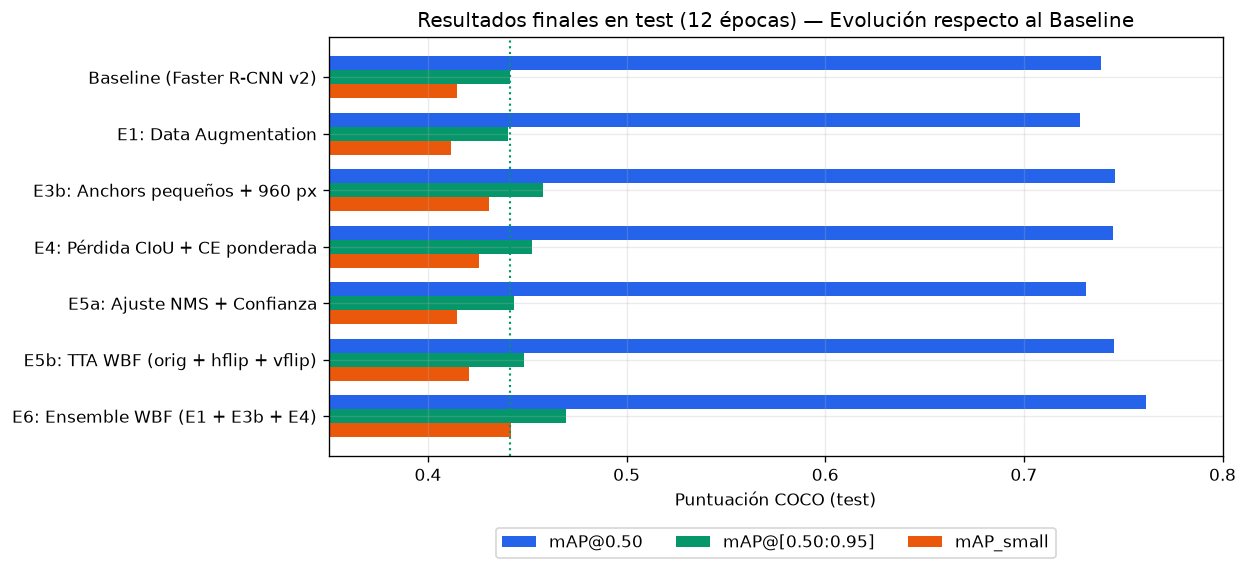

In [8]:
EXPERIMENTOS_FINALES = [
    NOMBRE_BASELINE,
    "E1: Data Augmentation",
    "E3b: Anchors pequeños + 960 px",
    "E4: Pérdida CIoU + CE ponderada",
    "E5a: Ajuste NMS + Confianza",
    "E5b: TTA WBF (orig + hflip + vflip)",
    "E6: Ensemble WBF (E1 + E3b + E4)",
]

filas_test = []
for nombre in EXPERIMENTOS_FINALES:
    m = cargar_metricas(EXPERIMENTOS[nombre]["dir"], "test")
    if m is None:
        continue
    pc = m.get("map_por_clase", {})
    t = m.get("tiempos", {})
    err = m.get("analisis_errores_05", {})
    filas_test.append({
        "Configuración (test final)": nombre,
        "mAP@0.50:0.95": m["map"],
        "mAP@0.50": m["map_50"],
        "mAP@0.75": m["map_75"],
        "mAP_small": m["map_small"],
        "AP Slippage": pc.get("Slippage", np.nan),
        "AP corrosion": pc.get("corrosion", np.nan),
        "AP crack": pc.get("crack", np.nan),
        "F1@0.5": err.get("f1", np.nan),
        "ms/img": t.get("ms_por_imagen", np.nan),
    })

if filas_test:
    df_test = pd.DataFrame(filas_test)
    mapas_test = df_test.set_index("Configuración (test final)")["mAP@0.50:0.95"]
    ref_test = mapas_test.get(NOMBRE_BASELINE, np.nan)
    df_test.insert(2, "ΔmAP vs Base", df_test["mAP@0.50:0.95"] - ref_test)

    display(
        df_test.style.format({
            "mAP@0.50:0.95": "{:.4f}",
            "ΔmAP vs Base": "{:+.4f}",
            "mAP@0.50": "{:.4f}",
            "mAP@0.75": "{:.4f}",
            "mAP_small": "{:.4f}",
            "AP Slippage": "{:.4f}",
            "AP corrosion": "{:.4f}",
            "AP crack": "{:.4f}",
            "F1@0.5": "{:.4f}",
            "ms/img": "{:.1f}",
        }, na_rep="—")
    )

    # Gráfica resumen de la evolución en test
    fig, ax = plt.subplots(figsize=(10.5, 4.9))
    y = np.arange(len(df_test))
    h = 0.25
    ax.barh(y - h, df_test["mAP@0.50"], height=h, label="mAP@0.50", color="#2563EB")
    ax.barh(y, df_test["mAP@0.50:0.95"], height=h, label="mAP@[0.50:0.95]", color="#059669")
    ax.barh(y + h, df_test["mAP_small"], height=h, label="mAP_small", color="#EA580C")
    if pd.notna(ref_test):
        ax.axvline(ref_test, color="#059669", linestyle=":", linewidth=1.3)
    ax.set_yticks(y)
    ax.set_yticklabels(df_test["Configuración (test final)"])
    ax.invert_yaxis()
    ax.set_xlim(0.35, 0.80)
    ax.set_xlabel("Puntuación COCO (test)")
    ax.set_title("Resultados finales en test (12 épocas) — Evolución respecto al Baseline")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    plt.tight_layout()
    plt.savefig(DIR_FIGURAS / "10_resultados_finales_test.png", bbox_inches="tight")
    plt.show()
else:
    print('Los archivos de la ronda original faltan en esta copia. Consulta las salidas guardadas del notebook o copia los resultados de referencia antes de volver a ejecutar esta celda.')

### Evaluación adicional de E3d a 20 épocas

El checkpoint de **960 px con anchors originales**, seleccionado por su mAP de 0,4868 en validación, obtuvo **0,4532 de mAP global**, **0,7368 de mAP@0,50**, **0,5064 de mAP@0,75**, **0,4244 de mAP_small** y **0,7329 de F1@0,50** en las 304 imágenes de test. E3b conserva el mayor mAP global entre los checkpoints individuales (0,4581). E3d obtiene un AP de `crack` de 0,3415, frente a 0,3373 de E3b.

Las métricas y predicciones se guardaron en `results/slippage_validation_split/faster_rcnn_resolucion_20ep/`. [Comparación con RetinaNet de una vista](resultados_ensemble.ipynb)

### Conclusiones principales para la presentación

1. **Resolución y geometría.** Con anchors originales, 960 px alcanza 0,4836 de mAP a 12 épocas y 0,4868 al repetir a 20 épocas. E3b, con 960 px y anchors ajustados, había obtenido 0,4739 en validación. Entre las configuraciones con evaluación de test guardada, E3b es el mejor checkpoint individual (0,4581).
2. **Optimización y aumentos.** Las dos recetas SGD, con MultiStepLR y coseno, quedan en torno a 0,448 en validación. Los aumentos llevaron el E1 original a 0,4854 y su repetición a 0,4685. Conviene indicar la ejecución al citar la métrica.
3. **Inferencia con el mismo E1 reentrenado.** Dos vistas mejoran el mAP global en 1,36 puntos porcentuales y el mAP_small en 1,32, con una ligera caída del mAP@0,50. La prueba original de tres vistas obtuvo 0,4986 con otro checkpoint de E1.
4. **Mejor configuración registrada.** E6, la fusión de tres Faster R-CNN, alcanza 0,5146 en validación y 0,4696 en test. Su mejora sobre el baseline en test es de 2,83 puntos porcentuales. El AP de `crack` pasa de 0,3215 a 0,3512 y el de `corrosion` de 0,3538 a 0,3680.
5. **Comparación con RetinaNet.** El aumento de resolución a 12 épocas se probó en ambas arquitecturas con anchors originales. Las 49 anotaciones de `Slippage` en validación limitan la interpretación de diferencias pequeñas en esa clase. La variante individual de 960 px a 20 épocas lidera en validación (0,4868) y obtiene 0,4532 en test. E3b sigue siendo el mejor checkpoint individual en test con 0,4581.